# Семантическая сегментация: DeepLabv3+ на Pascal VOC 2012

**Что делаем.** Обучаем DeepLabv3+ с энкодером ResNet-50, предобученным на ImageNet, относить каждый пиксель картинки к одному из 21 класса Pascal VOC 2012 (фон и 20 объектов). Качество считаем через IoU и Dice по каждому классу, накопленные по матрице ошибок всего набора, как в официальном протоколе VOC. Эксперимент: два одинаковых обучения с разными аугментациями: базовыми (изменение размера и отражение) и сильными (случайный масштаб, кроп, цветовой jitter).

**Содержание.**
1. Настройка
2. Теория: сегментация, DeepLabv3+, dilated-свёртки, IoU и Dice
3. Данные: Pascal VOC 2012
4. Метрики по матрице ошибок
5. Модель
6. Обучение: два эксперимента с аугментациями
7. Оценка на тесте: IoU и Dice по классам
8. Примеры предсказаний
9. Сравнительный анализ экспериментов и контрольные вопросы
10. Выводы


## 1. Настройка

In [13]:
import csv
import io
import json
import math
import platform
import random
import sys
import time
import warnings
from collections import Counter, deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import segmentation_models_pytorch as smp
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from matplotlib.patches import Patch
from PIL import Image
from torch.optim import SGD
from tqdm import tqdm as _tqdm

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


def tqdm(*args, **kwargs):
    kwargs = {"file": sys.stdout, "mininterval": 1.0, "dynamic_ncols": True, **kwargs}
    return _tqdm(*args, **kwargs)


SMOKE = False   # True — быстрая проверка пайплайна, False — полное обучение

TASK_DIR = Path.cwd()
assert (TASK_DIR / "voc_deeplab.ipynb").exists(), "Ноутбук нужно запускать из папки task-1-2-segmentation-a"
DATA = TASK_DIR / "data" / ("smoke" if SMOKE else "voc")               # картинки JPEG, маски PNG, списки сплитов
RESULTS = TASK_DIR / "results" / "smoke" if SMOKE else TASK_DIR / "results"
CKPT = TASK_DIR / "checkpoints" / ("smoke" if SMOKE else "")
SEED = 2012

HF_DATASET, HF_CONFIG = "shijli/voc2012", "segmentation"   # зеркало VOC 2012 на HuggingFace, маски хранят коды классов
CLASS_NAMES = ["background", "aeroplane", "bicycle", "bird", "boat", "bottle", "bus", "car", "cat", "chair", "cow",
               "diningtable", "dog", "horse", "motorbike", "person", "pottedplant", "sheep", "sofa", "train", "tvmonitor"]
NUM_CLASSES = len(CLASS_NAMES)
IGNORE = 255   # код границы объектов в разметке VOC: не участвует ни в loss, ни в метриках

DATA_CFG = dict(train=None, val=164, test=None, threads=8)   # val отрезается от официального train, официальный val служит тестом
BASE_CFG = dict(encoder="resnet50", epochs=30, batch_size=8, crop=512, lr_encoder=0.01, lr_decoder=0.1, momentum=0.9,
                weight_decay=1e-4, poly_power=0.9, warmup_iters=100, loader_threads=6, log_every=20, max_iters_per_epoch=None)
# Эксперимент: одна модель и одно расписание, разные аугментации
EXPERIMENTS = [dict(name="deeplab_basic", aug="basic"), dict(name="deeplab_strong", aug="strong")]
if SMOKE:
    DATA_CFG.update(train=16, val=8, test=8)
    BASE_CFG.update(epochs=2, batch_size=2, crop=256, warmup_iters=2, log_every=1, max_iters_per_epoch=4)
RUNS = [{**BASE_CFG, **e} for e in EXPERIMENTS]


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def env_info():
    info = {"python": sys.version.split()[0], "platform": platform.platform(), "torch": torch.__version__,
            "smp": smp.__version__, "cuda_available": torch.cuda.is_available()}
    if torch.cuda.is_available():
        info.update(cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0), arch_list=torch.cuda.get_arch_list())
    return info


def write_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, ensure_ascii=False, indent=1), encoding="utf-8")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"   # смешанная точность bf16: быстрее и экономнее по памяти
torch.backends.cudnn.benchmark = True
seed_everything(SEED)
if device.type != "cuda":
    print("ВНИМАНИЕ: CUDA недоступна, всё пойдёт на CPU и будет очень медленно.")
print(json.dumps(env_info(), ensure_ascii=False, indent=1))

{
 "python": "3.12.0",
 "platform": "Windows-10-10.0.19045-SP0",
 "torch": "2.11.0+cu128",
 "smp": "0.6.0",
 "cuda_available": true,
 "cuda": "12.8",
 "gpu": "NVIDIA GeForce RTX 5060",
 "arch_list": [
  "sm_75",
  "sm_80",
  "sm_86",
  "sm_90",
  "sm_100",
  "sm_120"
 ]
}


## 2. Теория

**Классификация, детекция, сегментация.** Классификация отвечает на вопрос «что на картинке» одной меткой. Детекция находит объекты и обводит каждый прямоугольником с меткой. Семантическая сегментация присваивает класс *каждому пикселю*: выход имеет то же разрешение, что вход, и для каждого пикселя содержит распределение по классам. Пиксели одного класса не разделяются на экземпляры (две собаки - одна область «dog»); этим семантическая сегментация отличается от instance-сегментации.

**Dilated (atrous) свёртки.** Обычная классификационная сеть за счёт пулинга уменьшает карту признаков в 32 раза, что губительно для плотного предсказания. Dilated-свёртка с коэффициентом *r* раздвигает элементы ядра 3×3 на *r* пикселей: поле зрения растёт как у ядра (2r+1)×(2r+1), а число параметров и разрешение карты остаются прежними. В DeepLab последняя стадия ResNet переводится на dilation 2 вместо stride 2, и энкодер выдаёт признаки с шагом 16, а не 32.

**DeepLabv3+.** Три части:
- *Энкодер* - ResNet-50 с dilated-свёртками в layer4 (output stride 16).
- *ASPP* (Atrous Spatial Pyramid Pooling) - параллельно к одной карте признаков применяются свёртка 1×1, три свёртки 3×3 с dilation 12, 24, 36 и глобальный пулинг; результаты конкатенируются. Так в каждом пикселе смешивается контекст разных масштабов: от локального до всей картинки.
- *Декодер* (добавлен в v3+) - выход ASPP увеличивается в 4 раза и объединяется с признаками энкодера шага 4 (низкоуровневые, с точными границами), затем две свёртки 3×3 и увеличение до размера входа. Это даёт более аккуратные границы, чем у DeepLabv3 без декодера.

**UNet для сравнения** - симметричный энкодер-декодер, где признаки *каждого* уровня энкодера конкатенируются с декодером (skip-соединения). DeepLabv3+ использует только один такой переход (шаг 4), а контекст набирает за счёт dilated-свёрток и ASPP, а не глубокого декодера.

**Метрики.** Для класса *c* по всем пикселям набора считаются TP (истина *c*, предсказано *c*), FP (предсказано *c*, истина другая) и FN (истина *c*, предсказано другое):

- IoU (Jaccard) = TP / (TP + FP + FN) - доля пересечения в объединении областей;
- Dice (F1) = 2·TP / (2·TP + FP + FN) - гармоническое среднее precision и recall; Dice = 2·IoU / (1 + IoU), так что он всегда не меньше IoU и мягче наказывает частичные ошибки;
- mIoU и mDice - среднее по классам, у каждого класса одинаковый вес независимо от числа пикселей;
- pixel accuracy - доля верных пикселей; на ней доминирует фон (почти ¾ пикселей VOC), поэтому в сегментации её почти не используют.

## 3. Данные: Pascal VOC 2012

**[Pascal VOC 2012](http://host.robots.ox.ac.uk/pascal/VOC/voc2012/)** - классический набор для сегментации: 20 классов объектов плюс фон, 1464 размеченных картинки в train и 1449 в val (разметка test не публикуется). Картинки около 500×375 px, маски — PNG с палитрой, в которых значение пикселя равно коду класса, а 255 отмечает границу объекта, которая не оценивается. Берём зеркало [shijli/voc2012](https://huggingface.co/datasets/shijli/voc2012) на HuggingFace (конфиг `segmentation`, 333 МБ parquet, аккаунт не нужен): маски в нём хранятся с кодами классов, а не цветами, как в некоторых других зеркалах.

**Сплиты.** Разметки официального test нет, поэтому:
- *test* - официальный val целиком (1449 картинок), на нём считаются итоговые метрики;
- *val* - 164 картинки, случайно отрезанные от официального train (seed 2012): по ним выбирается лучшая эпоха;
- *train* - оставшиеся 1300 картинок.

В `SMOKE`-режиме все три части берутся потоком из официального val (16/8/8 картинок).

In [ ]:
def hf_split(split):
    # Image(decode=False) отдаёт сырые байты файлов: картинки сохраняем как есть, маски декодируем через PIL
    from datasets import Image as HFImage, load_dataset
    ds = load_dataset(HF_DATASET, HF_CONFIG, split=split, streaming=SMOKE)
    return ds.cast_column("image", HFImage(decode=False)).cast_column("mask", HFImage(decode=False))


def decode_mask(buf):
    # Палитровый PNG → массив кодов классов. cv2 здесь не годится: он разворачивает палитру в цвета и теряет коды
    return np.array(Image.open(io.BytesIO(buf)))


def imread_rgb(path):
    return cv2.cvtColor(cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def read_mask(path):
    return np.array(Image.open(path))


def save_row(row, sub):
    img_rel, mask_rel = f"{sub}/images/{row['id']}.jpg", f"{sub}/masks/{row['id']}.png"
    img_path, mask_path = DATA / img_rel, DATA / mask_rel
    if not (img_path.exists() and mask_path.exists()):
        img_path.parent.mkdir(parents=True, exist_ok=True)
        mask_path.parent.mkdir(parents=True, exist_ok=True)
        buf = row["image"]["bytes"]
        if buf[:2] != b"\xff\xd8":   # если не JPEG, то перекодируем
            img = cv2.imdecode(np.frombuffer(buf, np.uint8), cv2.IMREAD_COLOR)
            buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 95])[1].tobytes()
        img_path.write_bytes(buf)
        Image.fromarray(decode_mask(row["mask"]["bytes"])).save(mask_path)   # PNG 8 бит без палитры: 0..20 и 255
    mask = read_mask(mask_path)
    classes = [int(c) for c in np.unique(mask) if c != IGNORE]
    return {"id": row["id"], "image": img_rel, "mask": mask_rel, "height": int(mask.shape[0]), "width": int(mask.shape[1]), "classes": classes}


def collect(ds, sub, limit, desc):
    records, pending, pool = [], deque(), ThreadPoolExecutor(DATA_CFG["threads"])
    pbar = tqdm(total=limit, desc=desc)
    try:
        for row in ds:
            pending.append(pool.submit(save_row, row, sub))
            while pending and (pending[0].done() or len(pending) >= DATA_CFG["threads"] * 2):
                records.append(pending.popleft().result())
                pbar.update(1)
            if limit and len(records) + len(pending) >= limit:
                break
        for f in pending:
            records.append(f.result())
            pbar.update(1)
    finally:
        pbar.close()
        pool.shutdown(wait=True)
    return records[:limit] if limit else records


def prepare_data():
    if (DATA / "test.json").exists():
        print(f"Данные уже подготовлены в {DATA}")
        return
    if SMOKE:
        # Всё из официального val потоком: небольшие непересекающиеся куски
        recs = collect(hf_split("validation"), "smoke", DATA_CFG["train"] + DATA_CFG["val"] + DATA_CFG["test"], "smoke")
        n_tr, n_va = DATA_CFG["train"], DATA_CFG["val"]
        parts = {"train": recs[:n_tr], "val": recs[n_tr:n_tr + n_va], "test": recs[n_tr + n_va:]}
    else:
        trainval = collect(hf_split("train"), "trainval", None, "официальный train")
        random.Random(SEED).shuffle(trainval)
        parts = {"val": trainval[:DATA_CFG["val"]], "train": trainval[DATA_CFG["val"]:],
                 "test": collect(hf_split("validation"), "test", None, "официальный val → test")}
    for name, recs in parts.items():
        write_json(DATA / f"{name}.json", sorted(recs, key=lambda r: r["id"]))


def load_split(name):
    recs = read_json(DATA / f"{name}.json")
    for r in recs:
        r["image_path"], r["mask_path"] = DATA / r["image"], DATA / r["mask"]
    return recs


prepare_data()
SPLITS = {s: load_split(s) for s in ("train", "val", "test")}
print({s: len(r) for s, r in SPLITS.items()})

segmentation/train-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B /  166MB            

segmentation/train-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

segmentation/validation-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B /  166MB            

segmentation/validation-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1464 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1449 [00:00<?, ? examples/s]

официальный train: 1464it [00:01, 784.16it/s]
официальный val → test: 1449it [00:01, 837.78it/s]
{'train': 1300, 'val': 164, 'test': 1449}


Раскраска классов - стандартная палитра VOC (цвет класса собирается из битов его номера). Ниже таблица: сколько картинок каждого класса в сплитах и какую долю пикселей train занимает класс. Фон занимает около 70 % пикселей, остальные классы делят оставшееся, причём неравномерно: это и есть причина, по которой pixel accuracy мало о чём говорит.

| Класс | train (1300 карт.) | val (164 карт.) | test (1449 карт.) | доля пикселей, train |
|---|---|---|---|---|
| background | 1297 | 163 | 1443 | 73.5% |
| aeroplane | 77 | 11 | 90 | 0.7% |
| bicycle | 59 | 6 | 79 | 0.3% |
| bird | 96 | 9 | 103 | 1.0% |
| boat | 66 | 12 | 72 | 0.6% |
| bottle | 70 | 17 | 96 | 0.5% |
| bus | 72 | 6 | 74 | 1.8% |
| car | 115 | 13 | 127 | 1.4% |
| cat | 118 | 13 | 119 | 2.7% |
| chair | 130 | 18 | 123 | 1.2% |
| cow | 59 | 5 | 71 | 0.8% |
| diningtable | 71 | 11 | 75 | 1.3% |
| dog | 103 | 18 | 128 | 1.6% |
| horse | 62 | 6 | 79 | 0.9% |
| motorbike | 71 | 10 | 76 | 1.2% |
| person | 392 | 50 | 446 | 4.8% |
| pottedplant | 72 | 10 | 85 | 0.6% |
| sheep | 61 | 2 | 57 | 1.0% |
| sofa | 80 | 13 | 90 | 1.4% |
| train | 77 | 6 | 84 | 1.6% |
| tvmonitor | 72 | 11 | 74 | 0.9% |

Граница объектов (код 255, не оценивается): 5.5% пикселей train.

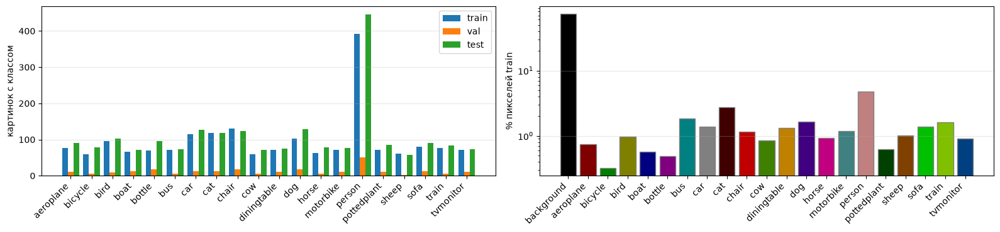

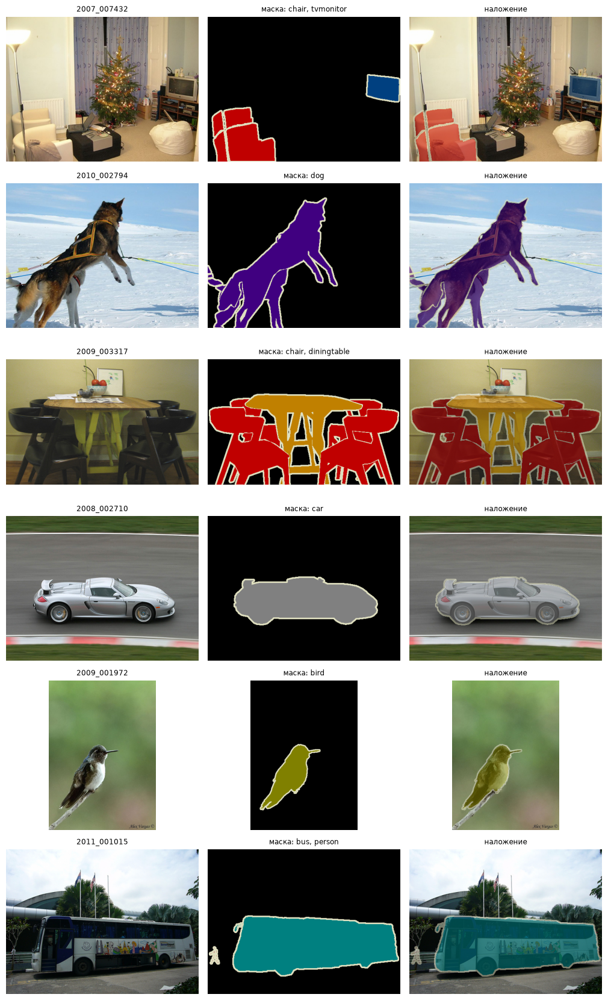

In [ ]:
def voc_palette():
    pal = np.zeros((256, 3), np.uint8)
    for i in range(256):
        c, r, g, b = i, 0, 0, 0
        for j in range(8):
            r |= ((c >> 0) & 1) << (7 - j)
            g |= ((c >> 1) & 1) << (7 - j)
            b |= ((c >> 2) & 1) << (7 - j)
            c >>= 3
        pal[i] = (r, g, b)
    return pal


PALETTE = voc_palette()   # PALETTE[255] белый, им рисуется граница


def colorize(mask):
    return PALETTE[mask]


def overlay(img, mask, alpha=0.55):
    # Полупрозрачная раскраска классов поверх картинки; фон не закрашивается, граница 255 - белым
    out = img.astype(np.float32)
    color = colorize(mask).astype(np.float32)
    keep = mask != 0
    out[keep] = (1 - alpha) * out[keep] + alpha * color[keep]
    return out.astype(np.uint8)


def class_list(mask_or_classes):
    classes = mask_or_classes if isinstance(mask_or_classes, list) else [int(c) for c in np.unique(mask_or_classes)]
    return ", ".join(CLASS_NAMES[c] for c in classes if c not in (0, IGNORE))


def show_grid(rows, titles, path=None, size=3.4):
    # rows - список строк, строка - список картинок; titles - такая же сетка подписей
    n_r, n_c = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(n_r, n_c, figsize=(size * n_c, size * n_r * 0.82), squeeze=False)
    for ax in axes.flat:
        ax.set_axis_off()
    for i, row in enumerate(rows):
        for j, img in enumerate(row):
            axes[i][j].imshow(img)
            axes[i][j].set_title(titles[i][j], fontsize=8.5)
    fig.tight_layout()
    if path:
        Path(path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=100)
    plt.show()


def pixel_shares(records):
    counts, void = np.zeros(NUM_CLASSES, np.int64), 0
    with ThreadPoolExecutor(DATA_CFG["threads"]) as pool:
        for m in pool.map(lambda r: read_mask(r["mask_path"]), records):
            counts += np.bincount(m[m != IGNORE].ravel(), minlength=NUM_CLASSES)
            void += int((m == IGNORE).sum())
    return counts / counts.sum(), void / (counts.sum() + void)


def dataset_summary(splits):
    img_counts = {s: Counter(c for r in recs for c in r["classes"]) for s, recs in splits.items()}
    share, void = pixel_shares(splits["train"])
    lines = ["| Класс | " + " | ".join(f"{s} ({len(r)} карт.)" for s, r in splits.items()) + " | доля пикселей, train |",
             "|---|" + "---|" * (len(splits) + 1)]
    lines += [f"| {name} | " + " | ".join(str(img_counts[s][c]) for s in splits) + f" | {share[c]:.1%} |" for c, name in enumerate(CLASS_NAMES)]
    display(Markdown("\n".join(lines)))
    display(Markdown(f"Граница объектов (код 255, не оценивается): {void:.1%} пикселей train."))
    write_json(RESULTS / "dataset_summary.json", {
        "images": {s: len(r) for s, r in splits.items()},
        "images_per_class": {s: {CLASS_NAMES[c]: n for c, n in sorted(cnt.items())} for s, cnt in img_counts.items()},
        "pixel_share_train": {CLASS_NAMES[c]: float(v) for c, v in enumerate(share)}, "void_share_train": float(void)})
    fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
    x = np.arange(1, NUM_CLASSES)
    for i, s in enumerate(splits):
        axes[0].bar(x + (i - 1) * 0.27, [img_counts[s][c] for c in x], width=0.27, label=s)
    axes[0].set_xticks(x, CLASS_NAMES[1:], rotation=45, ha="right")
    axes[0].set_ylabel("картинок с классом")
    axes[0].legend()
    axes[1].bar(np.arange(NUM_CLASSES), share * 100, color=[tuple(c / 255) for c in PALETTE[:NUM_CLASSES]], edgecolor="gray")
    axes[1].set_xticks(np.arange(NUM_CLASSES), CLASS_NAMES, rotation=45, ha="right")
    axes[1].set_ylabel("% пикселей train")
    axes[1].set_yscale("log")
    for ax in axes:
        ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    fig.savefig(RESULTS / "dataset_classes.png", dpi=110)
    plt.show()


dataset_summary(SPLITS)

sample = random.Random(SEED).sample(SPLITS["train"], min(6, len(SPLITS["train"])))
show_grid([[imread_rgb(r["image_path"]), colorize(read_mask(r["mask_path"])), overlay(imread_rgb(r["image_path"]), read_mask(r["mask_path"]))] for r in sample],
          [[r["id"], "маска: " + class_list(r["classes"]), "наложение"] for r in sample], path=RESULTS / "dataset_examples.png")

## 4. Метрики по матрице ошибок

Протокол VOC: по всем пикселям тестового набора накапливается матрица ошибок 21×21 (строка — истинный класс, столбец — предсказанный), пиксели границы 255 пропускаются. Из неё для каждого класса получаются TP (диагональ), FP (сумма столбца без диагонали) и FN (сумма строки без диагонали), а из них IoU и Dice. Класс, которого нет ни в истине, ни в предсказании, из среднего исключается. Та же функция по матрице одной картинки даёт метрики этой картинки.

Матрица считается на GPU через `bincount` по индексу `21·истина + предсказание`. Ниже три проверки с заранее известным ответом.

In [ ]:
def confusion_matrix(pred, gt, n=NUM_CLASSES):
    # pred, gt - целочисленные тензоры одной формы; пиксели с gt == IGNORE пропускаются → матрица n×n
    k = gt != IGNORE
    idx = gt[k].long() * n + pred[k].long()
    return torch.bincount(idx, minlength=n * n).reshape(n, n)


def metrics_from_confusion(cm):
    cm = np.asarray(cm, np.float64)
    tp = np.diag(cm)
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    with np.errstate(invalid="ignore", divide="ignore"):
        iou = np.where(tp + fp + fn > 0, tp / (tp + fp + fn), np.nan)
        dice = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), np.nan)
    return {"pixel_acc": float(tp.sum() / max(cm.sum(), 1)), "mIoU": float(np.nanmean(iou)), "mDice": float(np.nanmean(dice)),
            "iou": iou.tolist(), "dice": dice.tolist(), "gt_share": (cm.sum(1) / max(cm.sum(), 1)).tolist()}


# ---------- Проверки ----------
_gt = torch.tensor([[0, 0, 1, 1], [0, 2, 2, IGNORE]])
_m = metrics_from_confusion(confusion_matrix(_gt, _gt))
assert _m["pixel_acc"] == 1.0 and _m["mIoU"] == 1.0 and _m["mDice"] == 1.0, "идеальное предсказание → единицы"

_m = metrics_from_confusion(confusion_matrix(torch.zeros_like(_gt), _gt))   # «всё фон»
assert abs(_m["pixel_acc"] - 3 / 7) < 1e-9 and abs(_m["iou"][0] - 3 / 7) < 1e-9 and _m["iou"][1] == 0 and _m["iou"][2] == 0
assert math.isnan(_m["iou"][3]) and abs(_m["mIoU"] - (3 / 7) / 3) < 1e-9, "классы без пикселей не входят в среднее"

_pred = torch.tensor([[0, 0, 1, 2], [0, 2, 2, 1]])   # один пиксель класса 1 назван классом 2; пиксель под границей не считается
_m = metrics_from_confusion(confusion_matrix(_pred, _gt))
# класс 1: TP=1, FN=1, FP=0 → IoU 1/2, Dice 2/3; класс 2: TP=2, FP=1, FN=0 → IoU 2/3, Dice 4/5
assert abs(_m["iou"][1] - 0.5) < 1e-9 and abs(_m["dice"][1] - 2 / 3) < 1e-9
assert abs(_m["iou"][2] - 2 / 3) < 1e-9 and abs(_m["dice"][2] - 0.8) < 1e-9
print("Проверки метрик пройдены")

Проверки метрик пройдены


## 5. Модель

DeepLabv3+ собирается библиотекой [segmentation_models_pytorch](https://github.com/qubvel-org/segmentation_models.pytorch): энкодер ResNet-50 с весами ImageNet (скачиваются с HuggingFace), output stride 16, ASPP с dilation 12/24/36, декодер с признаками шага 4, голова на 21 класс. Ниже число параметров по частям, фактические dilation-коэффициенты и формы карт признаков на пробном входе: энкодер уменьшает картинку до шага 16 (а не 32, как обычный ResNet), а выход модели имеет разрешение входа.

In [17]:
def build_model(cfg, pretrained=True):
    model = smp.DeepLabV3Plus(encoder_name=cfg["encoder"], encoder_weights="imagenet" if pretrained else None,
                              encoder_output_stride=16, classes=NUM_CLASSES)
    return model.to(device)


def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6


_model = build_model(RUNS[0])
print(f"Параметров: всего {count_params(_model):.1f} млн; энкодер {count_params(_model.encoder):.1f}, "
      f"декодер с ASPP {count_params(_model.decoder):.2f}, голова {count_params(_model.segmentation_head):.3f}")
aspp_rates = sorted({m.dilation[0] for m in _model.decoder.modules() if isinstance(m, torch.nn.Conv2d) and m.dilation[0] > 1})
enc_rates = sorted({m.dilation[0] for m in _model.encoder.modules() if isinstance(m, torch.nn.Conv2d) and m.dilation[0] > 1})
print("Dilation в ASPP:", aspp_rates, "; dilation в энкодере (layer4 вместо stride 32):", enc_rates)
_model.eval()
with torch.no_grad():
    x = torch.zeros(1, 3, 256, 320, device=device)
    print("Карты признаков энкодера (каналы, высота, ширина):", [tuple(f.shape[1:]) for f in _model.encoder(x)])
    print("Выход модели:", tuple(_model(x).shape), "— логиты 21 класса в разрешении входа")
del _model

Параметров: всего 26.7 млн; энкодер 23.5, декодер с ASPP 3.17, голова 0.005
Dilation в ASPP: [12, 24, 36] ; dilation в энкодере (layer4 вместо stride 32): [2]
Карты признаков энкодера (каналы, высота, ширина): [(3, 256, 320), (64, 128, 160), (256, 64, 80), (512, 32, 40), (1024, 16, 20), (2048, 16, 20)]
Выход модели: (1, 21, 256, 320) — логиты 21 класса в разрешении входа


## 6. Обучение: два эксперимента с аугментациями

Обучаются две одинаковые модели с одинаковым расписанием, различается только подготовка обучающих картинок:

- **basic** - длинная сторона приводится к 512 px, картинка дополняется до 512×512 (маска - кодом 255, который не учитывается), случайное горизонтальное отражение. Сеть всегда видит объекты в одном масштабе.
- **strong** - случайный масштаб 0,5–2,0, дополнение до 512 и случайный кроп 512×512, отражение, цветовой jitter (яркость, контраст, насыщенность +-25 %). Стандартный набор для DeepLab на VOC: объекты встречаются в разных масштабах и положениях, часть картинки обрезается.

**Схема обучения.** Кросс-энтропия с `ignore_index = 255`; SGD с моментом 0,9 и Nesterov, weight decay 10⁻⁴. Темп обучения у энкодера 0,01, у декодера и головы в 10 раз больше (они инициализируются случайно), разогрев 100 итераций, затем полиномиальное затухание (1 − t/T)^0,9, как в статьях DeepLab. Батч 8, 30 эпох по 162 итерации, bf16. Неполный последний батч эпохи отбрасывается, чтобы BatchNorm не получал батчи из одной-двух картинок.

**Валидация** после каждой эпохи на 164 отложенных картинках в полном разрешении (с дополнением до кратного 16). Лучшая по mIoU эпоха сохраняется в `checkpoints/<имя>/best.pt`, чекпоинт для продолжения - в `latest.pt`, логи - в `results/<имя>/`. Батчи готовят потоки, не процессы (особенность Jupyter на Windows).

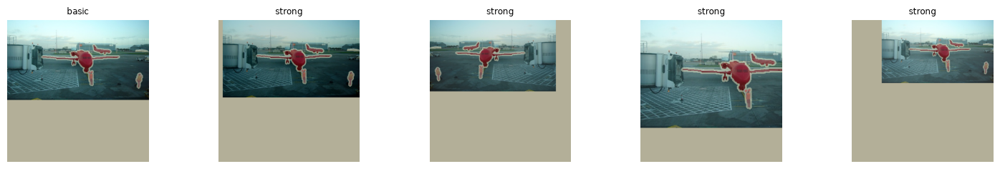

In [ ]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32) * 255   # статистики ImageNet: так был обучен энкодер
STD = np.array([0.229, 0.224, 0.225], np.float32) * 255


def to_input(img):
    # uint8 RGB H×W×3 в float тензор 3×H×W
    return torch.from_numpy(((img.astype(np.float32) - MEAN) / STD).transpose(2, 0, 1).copy())


def pad_pair(img, mask, h, w):
    # Дополнение снизу и справа: картинка средним цветом (после нормировки это нули), маска кодом IGNORE
    ph, pw = max(0, h - img.shape[0]), max(0, w - img.shape[1])
    if ph or pw:
        img = cv2.copyMakeBorder(img, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=MEAN.tolist())
        mask = cv2.copyMakeBorder(mask, 0, ph, 0, pw, cv2.BORDER_CONSTANT, value=IGNORE)
    return img, mask


def resize_pair(img, mask, scale):
    h, w = mask.shape
    size = (max(1, round(w * scale)), max(1, round(h * scale)))
    return cv2.resize(img, size, interpolation=cv2.INTER_LINEAR), cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST)


def color_jitter(img, b=0.25, c=0.25, s=0.25):
    img = img.astype(np.float32) * random.uniform(1 - b, 1 + b)        # яркость
    mean = img.mean()
    img = (img - mean) * random.uniform(1 - c, 1 + c) + mean            # контраст
    gray = img.mean(axis=2, keepdims=True)
    img = (img - gray) * random.uniform(1 - s, 1 + s) + gray            # насыщенность
    return np.clip(img, 0, 255).astype(np.uint8)


class SegDataset:
    def __init__(self, records, aug, crop):
        self.records, self.aug, self.crop = records, aug, crop

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        img, mask = imread_rgb(r["image_path"]), read_mask(r["mask_path"])
        c = self.crop
        if self.aug == "strong":
            img, mask = resize_pair(img, mask, random.uniform(0.5, 2.0))
            img = color_jitter(img)
        else:
            img, mask = resize_pair(img, mask, c / max(mask.shape))
        img, mask = pad_pair(img, mask, c, c)
        y0, x0 = random.randint(0, mask.shape[0] - c), random.randint(0, mask.shape[1] - c)
        img, mask = img[y0:y0 + c, x0:x0 + c], mask[y0:y0 + c, x0:x0 + c]
        if random.random() < 0.5:
            img, mask = img[:, ::-1], mask[:, ::-1]
        return to_input(np.ascontiguousarray(img)), torch.from_numpy(np.ascontiguousarray(mask).astype(np.int64))


class EvalDataset:
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        return imread_rgb(r["image_path"]), read_mask(r["mask_path"])


def iterate_batches(ds, indices, batch_size, threads):
    # Батчи готовятся потоками с опережением; процессы в Jupyter на Windows не видят классов ноутбука
    chunks = [indices[i:i + batch_size] for i in range(0, len(indices), batch_size)]
    load = lambda chunk: [ds[j] for j in chunk]
    with ThreadPoolExecutor(threads) as pool:
        futures = deque(pool.submit(load, c) for c in chunks[:threads])
        for k in range(len(chunks)):
            if k + threads < len(chunks):
                futures.append(pool.submit(load, chunks[k + threads]))
            yield futures.popleft().result()


aug_demo = SegDataset(SPLITS["train"][:1] * 4, "strong", RUNS[0]["crop"])
basic_demo = SegDataset(SPLITS["train"][:1], "basic", RUNS[0]["crop"])
_show = lambda x, m: overlay(np.clip(x.numpy().transpose(1, 2, 0) * STD + MEAN, 0, 255).astype(np.uint8), m.numpy().astype(np.uint8))
show_grid([[_show(*basic_demo[0])] + [_show(*aug_demo[i]) for i in range(4)]],
          [["basic"] + ["strong"] * 4], path=RESULTS / "augmentations.png", size=3.0)

Инференс в полном разрешении: картинка дополняется до кратного 16, логиты обрезаются до исходного размера. Валидация и тест идут по одной картинке (размеры в VOC разные), матрица ошибок накапливается на GPU.

In [ ]:
def pad_to_multiple(img, m=16):
    h, w = img.shape[:2]
    return cv2.copyMakeBorder(img, 0, math.ceil(h / m) * m - h, 0, math.ceil(w / m) * m - w, cv2.BORDER_CONSTANT, value=MEAN.tolist())


@torch.no_grad()
def predict_logits(model, img):
    # → логиты [21, h, w] в разрешении картинки
    h, w = img.shape[:2]
    x = to_input(pad_to_multiple(img))[None].to(device, non_blocking=True)
    with torch.autocast(device.type, dtype=torch.bfloat16, enabled=AMP):
        logits = model(x)
    return logits[0, :, :h, :w].float()


def predict_mask(model, img):
    return predict_logits(model, img).argmax(0).to(torch.uint8).cpu().numpy()


@torch.no_grad()
def evaluate(model, records, desc, per_image=False):
    # Матрица ошибок по всем пикселям набора; per_image - ещё и метрики каждой картинки
    model.eval()
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.int64, device=device)
    rows = []
    ds = EvalDataset(records)
    for k, batch in enumerate(tqdm(iterate_batches(ds, list(range(len(ds))), 1, 4), total=len(ds), desc=desc, leave=False)):
        img, mask = batch[0]
        pred = predict_logits(model, img).argmax(0)
        cm_i = confusion_matrix(pred, torch.from_numpy(mask.astype(np.int64)).to(device))
        cm += cm_i
        if per_image:
            m = metrics_from_confusion(cm_i.cpu().numpy())
            rows.append({"id": records[k]["id"], "mIoU": m["mIoU"], "mDice": m["mDice"], "pixel_acc": m["pixel_acc"]})
    res = metrics_from_confusion(cm.cpu().numpy())
    res["confusion"] = cm.cpu().numpy().tolist()
    return (res, rows) if per_image else res

deeplab_basic: аугментации «basic», 1300 картинок, 162 итераций в эпохе, 30 эпох; val 164
deeplab_basic, эпоха 1: 100%|██████████| 162/162 [00:45<00:00,  3.52it/s, VRAM=3.6G, loss=0.846, lr=0.0099]
[deeplab_basic, эпоха 1] val: mIoU 0.177, mDice 0.253, pixel acc 0.748  ← лучшая
deeplab_basic, эпоха 2: 100%|██████████| 162/162 [00:34<00:00,  4.72it/s, VRAM=3.6G, loss=0.604, lr=0.0096]
[deeplab_basic, эпоха 2] val: mIoU 0.268, mDice 0.372, pixel acc 0.787  ← лучшая
deeplab_basic, эпоха 3: 100%|██████████| 162/162 [00:31<00:00,  5.13it/s, VRAM=3.6G, loss=0.511, lr=0.0093]
[deeplab_basic, эпоха 3] val: mIoU 0.380, mDice 0.500, pixel acc 0.846  ← лучшая
deeplab_basic, эпоха 4: 100%|██████████| 162/162 [00:31<00:00,  5.19it/s, VRAM=3.6G, loss=0.430, lr=0.0090]
[deeplab_basic, эпоха 4] val: mIoU 0.426, mDice 0.552, pixel acc 0.844  ← лучшая
deeplab_basic, эпоха 5: 100%|██████████| 162/162 [00:31<00:00,  5.11it/s, VRAM=3.6G, loss=0.382, lr=0.0087]
[deeplab_basic, эпоха 5] val: mIoU 0.413, mDic

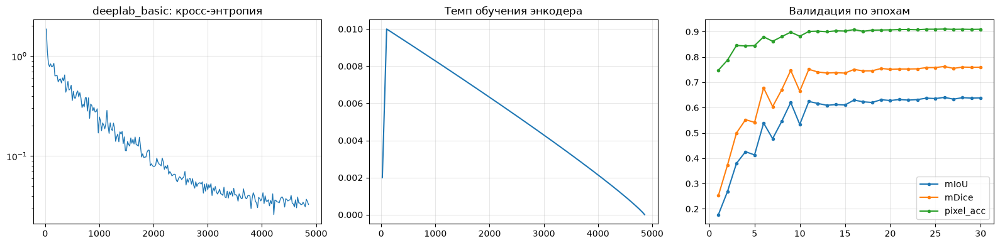

deeplab_strong: аугментации «strong», 1300 картинок, 162 итераций в эпохе, 30 эпох; val 164
deeplab_strong, эпоха 1: 100%|██████████| 162/162 [00:30<00:00,  5.25it/s, VRAM=3.6G, loss=1.141, lr=0.0099]
[deeplab_strong, эпоха 1] val: mIoU 0.103, mDice 0.144, pixel acc 0.723  ← лучшая
deeplab_strong, эпоха 2: 100%|██████████| 162/162 [00:30<00:00,  5.30it/s, VRAM=3.6G, loss=0.995, lr=0.0096]
[deeplab_strong, эпоха 2] val: mIoU 0.178, mDice 0.254, pixel acc 0.769  ← лучшая
deeplab_strong, эпоха 3: 100%|██████████| 162/162 [00:30<00:00,  5.35it/s, VRAM=3.6G, loss=0.875, lr=0.0093]
[deeplab_strong, эпоха 3] val: mIoU 0.257, mDice 0.357, pixel acc 0.790  ← лучшая
deeplab_strong, эпоха 4: 100%|██████████| 162/162 [00:31<00:00,  5.18it/s, VRAM=3.6G, loss=0.650, lr=0.0090]
[deeplab_strong, эпоха 4] val: mIoU 0.312, mDice 0.432, pixel acc 0.803  ← лучшая
deeplab_strong, эпоха 5: 100%|██████████| 162/162 [00:31<00:00,  5.21it/s, VRAM=3.6G, loss=0.641, lr=0.0087]
[deeplab_strong, эпоха 5] val: mIoU

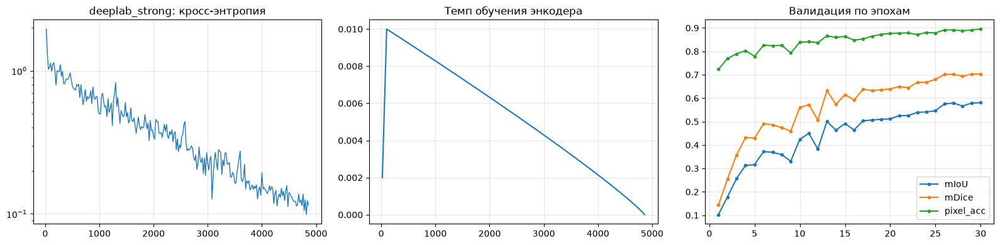

In [20]:
def append_csv(path, row):
    path.parent.mkdir(parents=True, exist_ok=True)
    new = not path.exists()
    with open(path, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, list(row))
        if new:
            w.writeheader()
        w.writerow({k: f"{v:.6g}" if isinstance(v, float) else v for k, v in row.items()})


def read_csv(path):
    if not Path(path).exists():
        return []
    with open(path, newline="", encoding="utf-8") as f:
        return [{k: (float(v) if v.replace(".", "", 1).replace("-", "", 1).replace("e", "", 1).isdigit() else v) for k, v in r.items() if v}
                for r in csv.DictReader(f)]


def lr_factor(it, total, cfg):
    if it < cfg["warmup_iters"]:
        return (it + 1) / cfg["warmup_iters"]
    return (1 - (it - cfg["warmup_iters"]) / max(1, total - cfg["warmup_iters"])) ** cfg["poly_power"]


def make_optimizer(model, cfg):
    groups = [{"params": list(model.encoder.parameters()), "lr": cfg["lr_encoder"], "base_lr": cfg["lr_encoder"]},
              {"params": [*model.decoder.parameters(), *model.segmentation_head.parameters()], "lr": cfg["lr_decoder"], "base_lr": cfg["lr_decoder"]}]
    return SGD(groups, momentum=cfg["momentum"], weight_decay=cfg["weight_decay"], nesterov=True)


def run_epoch(model, opt, cfg, epoch, it, total_iters, log_path):
    ds = SegDataset(SPLITS["train"], cfg["aug"], cfg["crop"])
    indices = list(range(len(ds)))
    random.shuffle(indices)
    n_iters = max(1, len(indices) // cfg["batch_size"])
    if cfg["max_iters_per_epoch"]:
        n_iters = min(n_iters, cfg["max_iters_per_epoch"])
    indices = indices[: n_iters * cfg["batch_size"]]
    model.train()
    loss_acc, n_acc, t_window = 0.0, 0, time.time()
    pbar = tqdm(iterate_batches(ds, indices, cfg["batch_size"], cfg["loader_threads"]), total=n_iters, desc=f"{cfg['name']}, эпоха {epoch}")
    for batch in pbar:
        factor = lr_factor(it, total_iters, cfg)
        for g in opt.param_groups:
            g["lr"] = g["base_lr"] * factor
        x = torch.stack([b[0] for b in batch]).to(device, non_blocking=True)
        y = torch.stack([b[1] for b in batch]).to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.bfloat16, enabled=AMP):
            logits = model(x)
        loss = F.cross_entropy(logits.float(), y, ignore_index=IGNORE)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        it, n_acc, loss_acc = it + 1, n_acc + 1, loss_acc + loss.detach()
        if it % cfg["log_every"] == 0:
            mem = torch.cuda.max_memory_allocated() / 2 ** 30 if device.type == "cuda" else 0.0
            mean_loss = float(loss_acc) / n_acc
            append_csv(log_path, {"iter": it, "epoch": epoch, "lr": opt.param_groups[0]["lr"], "loss": mean_loss,
                                  "it_per_s": n_acc / (time.time() - t_window), "mem_gb": mem})
            pbar.set_postfix(loss=f"{mean_loss:.3f}", lr=f"{opt.param_groups[0]['lr']:.4f}", VRAM=f"{mem:.1f}G")
            loss_acc, n_acc, t_window = 0.0, 0, time.time()
    pbar.close()
    return it


def train(cfg, restart=False):
    run_dir, ckpt_dir = RESULTS / cfg["name"], CKPT / cfg["name"]
    latest = ckpt_dir / "latest.pt"
    restart = restart or SMOKE
    seed_everything(SEED)
    model = build_model(cfg)
    opt = make_optimizer(model, cfg)
    done, best, it, elapsed_before = 0, None, 0, 0.0
    if latest.exists() and not restart:
        ck = torch.load(latest, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        done, best, it, elapsed_before = ck["done"], ck["best"], ck["iter"], ck["elapsed"]
        print(f"Продолжаю {cfg['name']}: выполнено {done} из {cfg['epochs']} эпох")
    elif restart:
        for p in (run_dir / "train_log.csv", run_dir / "val_log.csv"):
            p.unlink(missing_ok=True)
    if done >= cfg["epochs"]:
        print(f"{cfg['name']}: модель уже обучена. Для переобучения: train(cfg, restart=True)")
        return read_json(run_dir / "summary.json")
    write_json(run_dir / "env.json", env_info())
    write_json(run_dir / "config.json", {**cfg, "data": DATA_CFG, "classes": CLASS_NAMES, "seed": SEED})
    iters_per_epoch = min(max(1, len(SPLITS["train"]) // cfg["batch_size"]), cfg["max_iters_per_epoch"] or 10 ** 9)
    total_iters = iters_per_epoch * cfg["epochs"]
    print(f"{cfg['name']}: аугментации «{cfg['aug']}», {len(SPLITS['train'])} картинок, {iters_per_epoch} итераций в эпохе, "
          f"{cfg['epochs']} эпох; val {len(SPLITS['val'])}")
    t_start = time.time()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    try:
        for epoch in range(done + 1, cfg["epochs"] + 1):
            it = run_epoch(model, opt, cfg, epoch, it, total_iters, run_dir / "train_log.csv")
            res = evaluate(model, SPLITS["val"], "val")
            append_csv(run_dir / "val_log.csv", {"epoch": epoch, "mIoU": res["mIoU"], "mDice": res["mDice"], "pixel_acc": res["pixel_acc"],
                                                 "elapsed_min": (elapsed_before + time.time() - t_start) / 60})
            mark = ""
            if best is None or res["mIoU"] > best:
                best, mark = res["mIoU"], "  ← лучшая"
                ckpt_dir.mkdir(parents=True, exist_ok=True)
                torch.save(model.state_dict(), ckpt_dir / "best.pt")
            print(f"[{cfg['name']}, эпоха {epoch}] val: mIoU {res['mIoU']:.3f}, mDice {res['mDice']:.3f}, pixel acc {res['pixel_acc']:.3f}{mark}")
            done = epoch
            ckpt_dir.mkdir(parents=True, exist_ok=True)
            torch.save({"done": done, "best": best, "iter": it, "elapsed": elapsed_before + time.time() - t_start,
                        "model": model.state_dict(), "opt": opt.state_dict()}, latest.with_suffix(".tmp"))
            latest.with_suffix(".tmp").replace(latest)
    except KeyboardInterrupt:
        print("Остановлено. Повторный запуск ячейки продолжит с последней завершённой эпохи.")
        return None
    total = elapsed_before + time.time() - t_start
    val_log = read_csv(run_dir / "val_log.csv")
    summary = {"name": cfg["name"], "aug": cfg["aug"], "epochs": cfg["epochs"], "iterations": it, "best_val_mIoU": best,
               "best_epoch": int(max(val_log, key=lambda r: r["mIoU"])["epoch"]), "total_minutes": round(total / 60, 1),
               "total_time": f"{int(total // 3600)} ч {int(total % 3600 // 60):02d} мин"}
    if device.type == "cuda":
        summary["max_vram_gb"] = round(torch.cuda.max_memory_allocated() / 2 ** 30, 2)
    write_json(run_dir / "summary.json", summary)
    del model, opt
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return summary


def plot_training(name):
    run = RESULTS / name
    tr, va = read_csv(run / "train_log.csv"), read_csv(run / "val_log.csv")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot([r["iter"] for r in tr], [r["loss"] for r in tr], linewidth=1)
    axes[0].set_yscale("log")
    axes[0].set_title(f"{name}: кросс-энтропия")
    axes[1].plot([r["iter"] for r in tr], [r["lr"] for r in tr])
    axes[1].set_title("Темп обучения энкодера")
    for k in ("mIoU", "mDice", "pixel_acc"):
        axes[2].plot([r["epoch"] for r in va], [r[k] for r in va], marker=".", label=k)
    axes[2].set_title("Валидация по эпохам")
    axes[2].legend()
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(run / "curves.png", dpi=110)
    plt.show()


for cfg in RUNS:
    summary = train(cfg)
    if summary is None:
        break
    print(summary)
    plot_training(cfg["name"])

## 7. Оценка на тесте: IoU и Dice по классам

Для каждой модели берутся лучшие по валидации веса, и на 1449 тестовых картинках в полном разрешении накапливается матрица ошибок. Таблица: IoU и Dice каждого класса для обоих экспериментов, внизу средние и pixel accuracy. Для сравнения - тривиальный предсказатель «всё фон»: его accuracy равна доле фона, а mIoU близок к нулю.

| Класс | доля пикселей | IoU deeplab_basic | IoU deeplab_strong | Dice deeplab_basic | Dice deeplab_strong |
|---|---|---|---|---|---|
| background | 73.3% | 0.920 | 0.911 | 0.958 | 0.953 |
| aeroplane | 0.8% | 0.808 | 0.802 | 0.894 | 0.890 |
| bicycle | 0.3% | 0.492 | 0.474 | 0.659 | 0.643 |
| bird | 0.9% | 0.761 | 0.770 | 0.864 | 0.870 |
| boat | 0.6% | 0.590 | 0.631 | 0.742 | 0.774 |
| bottle | 0.8% | 0.616 | 0.627 | 0.762 | 0.770 |
| bus | 1.8% | 0.841 | 0.852 | 0.913 | 0.920 |
| car | 1.5% | 0.789 | 0.752 | 0.882 | 0.859 |
| cat | 2.3% | 0.786 | 0.774 | 0.880 | 0.872 |
| chair | 0.9% | 0.254 | 0.236 | 0.405 | 0.382 |
| cow | 1.2% | 0.660 | 0.630 | 0.795 | 0.773 |
| diningtable | 1.2% | 0.494 | 0.510 | 0.662 | 0.675 |
| dog | 2.1% | 0.715 | 0.694 | 0.834 | 0.820 |
| horse | 1.1% | 0.633 | 0.607 | 0.775 | 0.756 |
| motorbike | 1.1% | 0.757 | 0.694 | 0.862 | 0.820 |
| person | 5.3% | 0.795 | 0.768 | 0.886 | 0.869 |
| pottedplant | 0.5% | 0.457 | 0.447 | 0.627 | 0.618 |
| sheep | 0.8% | 0.770 | 0.765 | 0.870 | 0.867 |
| sofa | 1.4% | 0.381 | 0.342 | 0.552 | 0.510 |
| train | 1.6% | 0.727 | 0.720 | 0.842 | 0.837 |
| tvmonitor | 0.7% | 0.613 | 0.478 | 0.760 | 0.646 |
| **среднее по классам** | | **0.660** | **0.642** | **0.782** | **0.768** |

| Модель | pixel accuracy | mIoU |
|---|---|---|
| deeplab_basic | 0.920 | 0.660 |
| deeplab_strong | 0.911 | 0.642 |
| «всё фон» | 0.733 | 0.035 |

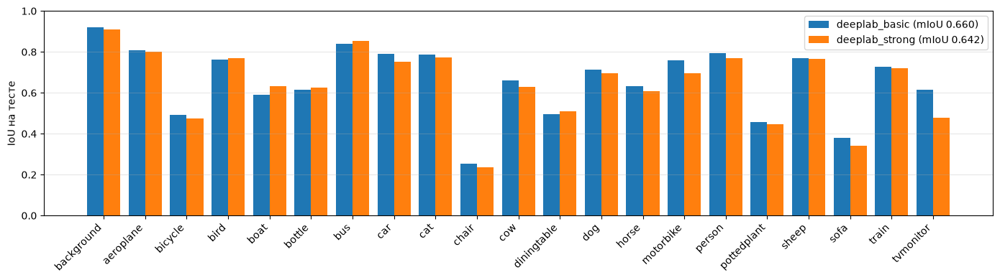

In [ ]:
def load_best(cfg):
    model = build_model(cfg, pretrained=False)
    model.load_state_dict(torch.load(CKPT / cfg["name"] / "best.pt", map_location=device))
    return model.eval()


def test_metrics():
    path = RESULTS / "eval" / "metrics.json"
    test_ids = [r["id"] for r in SPLITS["test"]]
    if path.exists() and not SMOKE:
        cached = read_json(path)
        if cached.get("test_ids") == test_ids and all(c["name"] in cached["runs"] for c in RUNS):
            print("Метрики на тесте уже посчитаны, читаю", path)
            return cached
    out = {"test_ids": test_ids, "runs": {}}
    for cfg in RUNS:
        model = load_best(cfg)
        res, rows = evaluate(model, SPLITS["test"], f"test {cfg['name']}", per_image=True)
        out["runs"][cfg["name"]] = res
        per_image = RESULTS / "eval" / f"per_image_{cfg['name']}.csv"
        per_image.unlink(missing_ok=True)
        for row in rows:
            append_csv(per_image, row)
        del model
    write_json(path, out)
    return out


TEST = test_metrics()
names = [cfg["name"] for cfg in RUNS]
share = TEST["runs"][names[0]]["gt_share"]
fmt = lambda v: "—" if v is None or v != v else f"{v:.3f}"   # NaN - класса нет ни в истине, ни в предсказании
lines = ["| Класс | доля пикселей | " + " | ".join(f"IoU {n}" for n in names) + " | " + " | ".join(f"Dice {n}" for n in names) + " |",
         "|---|---|" + "---|" * (2 * len(names))]
for c, cls in enumerate(CLASS_NAMES):
    lines.append(f"| {cls} | {share[c]:.1%} | " + " | ".join(fmt(TEST["runs"][n]["iou"][c]) for n in names) + " | "
                 + " | ".join(fmt(TEST["runs"][n]["dice"][c]) for n in names) + " |")
lines.append("| **среднее по классам** | | " + " | ".join(f"**{TEST['runs'][n]['mIoU']:.3f}**" for n in names) + " | "
             + " | ".join(f"**{TEST['runs'][n]['mDice']:.3f}**" for n in names) + " |")
display(Markdown("\n".join(lines)))
baseline_miou = share[0] / sum(1 for s in share if s > 0)
display(Markdown("| Модель | pixel accuracy | mIoU |\n|---|---|---|\n"
                 + "".join(f"| {n} | {TEST['runs'][n]['pixel_acc']:.3f} | {TEST['runs'][n]['mIoU']:.3f} |\n" for n in names)
                 + f"| «всё фон» | {share[0]:.3f} | {baseline_miou:.3f} |"))

fig, ax = plt.subplots(figsize=(14, 4))
x = np.arange(NUM_CLASSES)
for i, n in enumerate(names):
    ax.bar(x + (i - 0.5) * 0.4, TEST["runs"][n]["iou"], width=0.4, label=f"{n} (mIoU {TEST['runs'][n]['mIoU']:.3f})")
ax.set_xticks(x, CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("IoU на тесте")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(RESULTS / "eval" / "iou_per_class.png", dpi=110)
plt.show()

Матрица ошибок лучшей модели, нормированная по строкам: ячейка (i, j) - какая доля пикселей класса i предсказана как j. Диагональ - recall класса; тёмные ячейки вне диагонали - характерные путаницы. Рядом список самых частых путаниц.

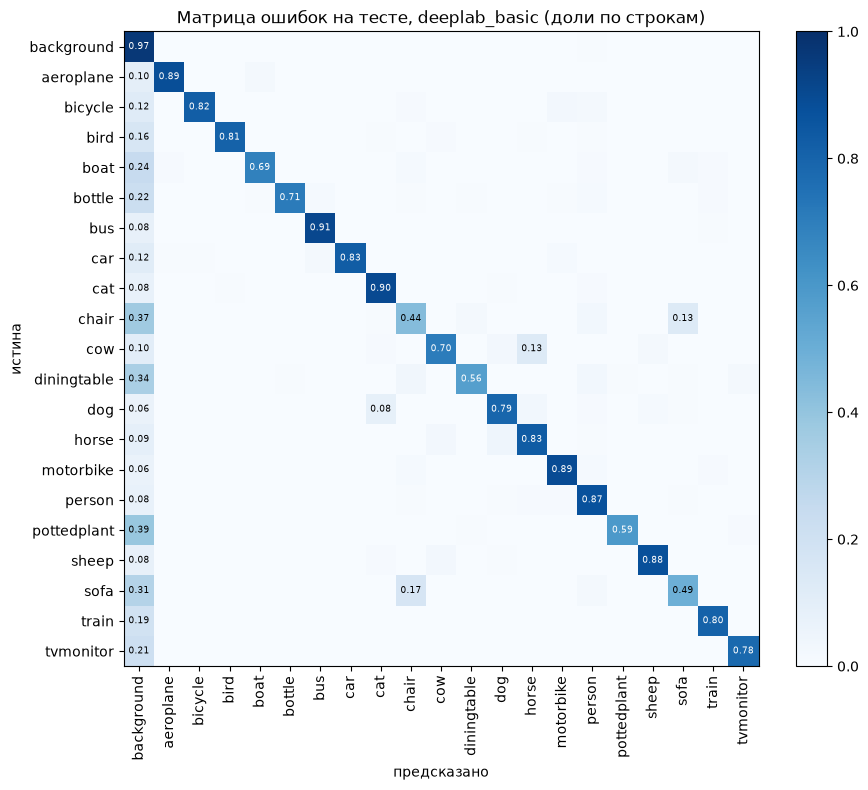

**Самые частые путаницы** (доля пикселей истинного класса, ушедшая в другой):

- pottedplant → background: 38.8%
- chair → background: 36.9%
- diningtable → background: 33.8%
- sofa → background: 30.9%
- boat → background: 24.3%
- bottle → background: 21.9%
- tvmonitor → background: 21.5%
- train → background: 19.1%
- sofa → chair: 16.7%
- bird → background: 15.9%

In [22]:
BEST_RUN = max(names, key=lambda n: TEST["runs"][n]["mIoU"])
cm = np.array(TEST["runs"][BEST_RUN]["confusion"], np.float64)
norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=90)
ax.set_yticks(range(NUM_CLASSES), CLASS_NAMES)
ax.set_xlabel("предсказано")
ax.set_ylabel("истина")
ax.set_title(f"Матрица ошибок на тесте, {BEST_RUN} (доли по строкам)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if norm[i, j] >= 0.05:
            ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if norm[i, j] > 0.5 else "black")
fig.colorbar(im, fraction=0.046)
fig.tight_layout()
fig.savefig(RESULTS / "eval" / f"confusion_{BEST_RUN}.png", dpi=110)
plt.show()

pairs = sorted(((norm[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and norm[i, j] > 0), reverse=True)[:10]
display(Markdown("**Самые частые путаницы** (доля пикселей истинного класса, ушедшая в другой):\n\n"
                 + "\n".join(f"- {CLASS_NAMES[i]} → {CLASS_NAMES[j]}: {v:.1%}" for v, i, j in pairs)))

## 8. Примеры предсказаний

Слева картинка и разметка, справа предсказания обеих моделей с наложением масок; в подписях - mIoU этой картинки. Первая сетка - случайные тестовые картинки, вторая - самые трудные для лучшей модели (минимальный mIoU картинки), третья — где сильные аугментации помогли больше всего.

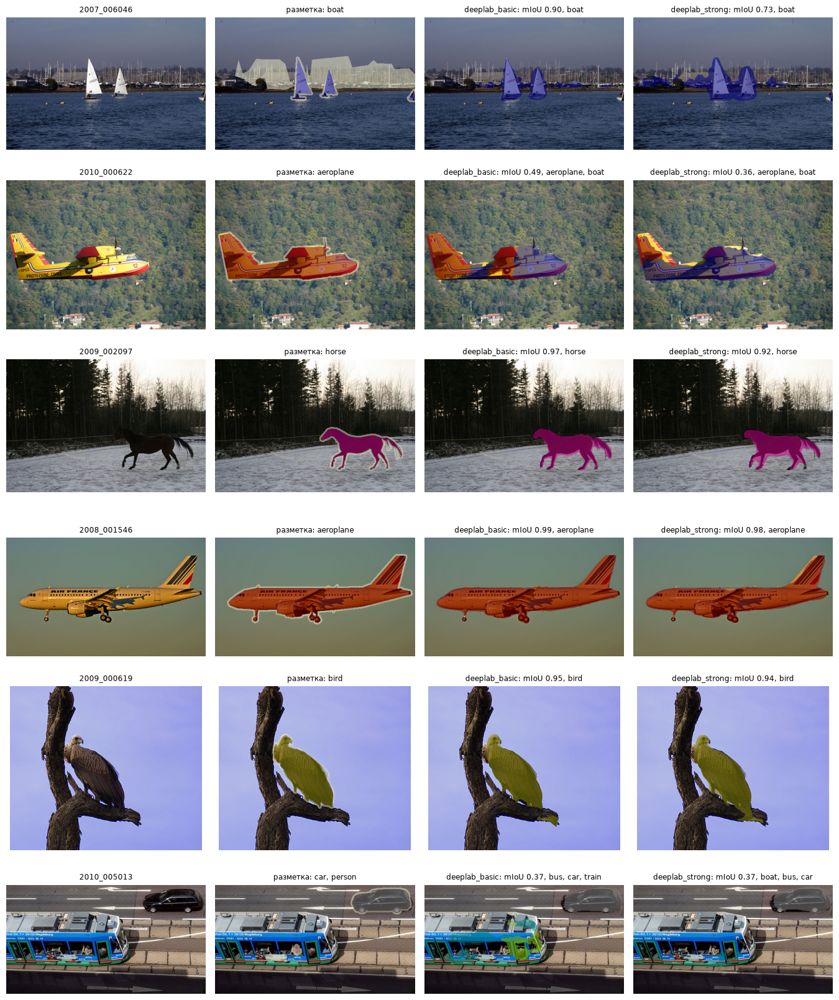

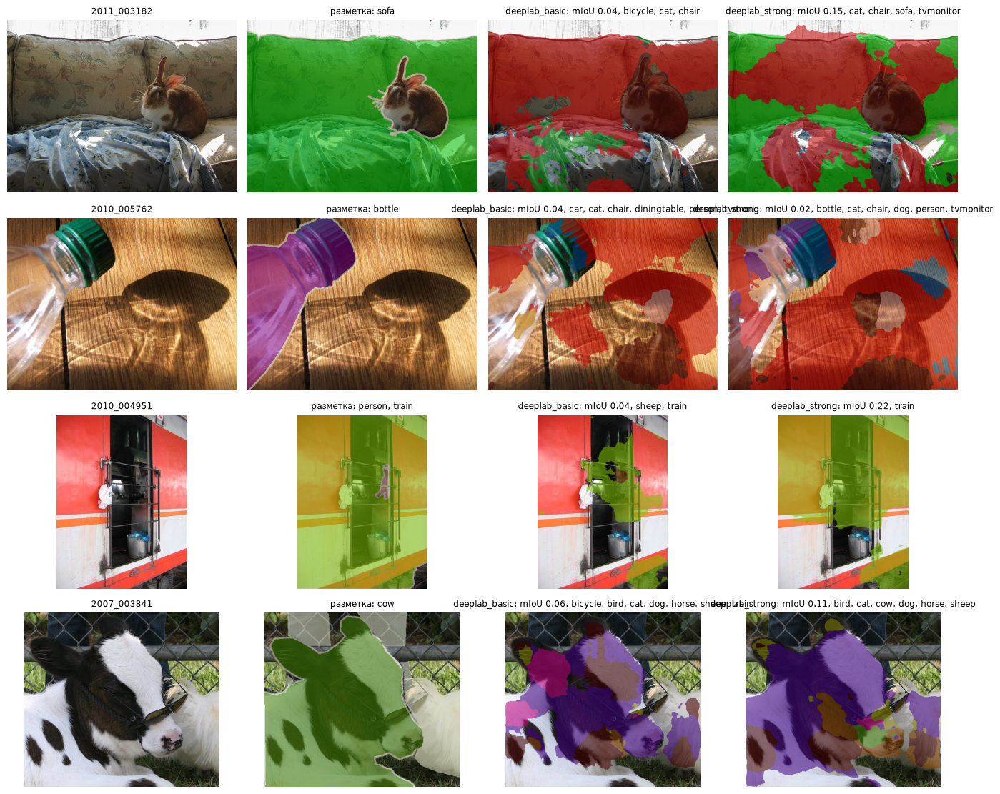

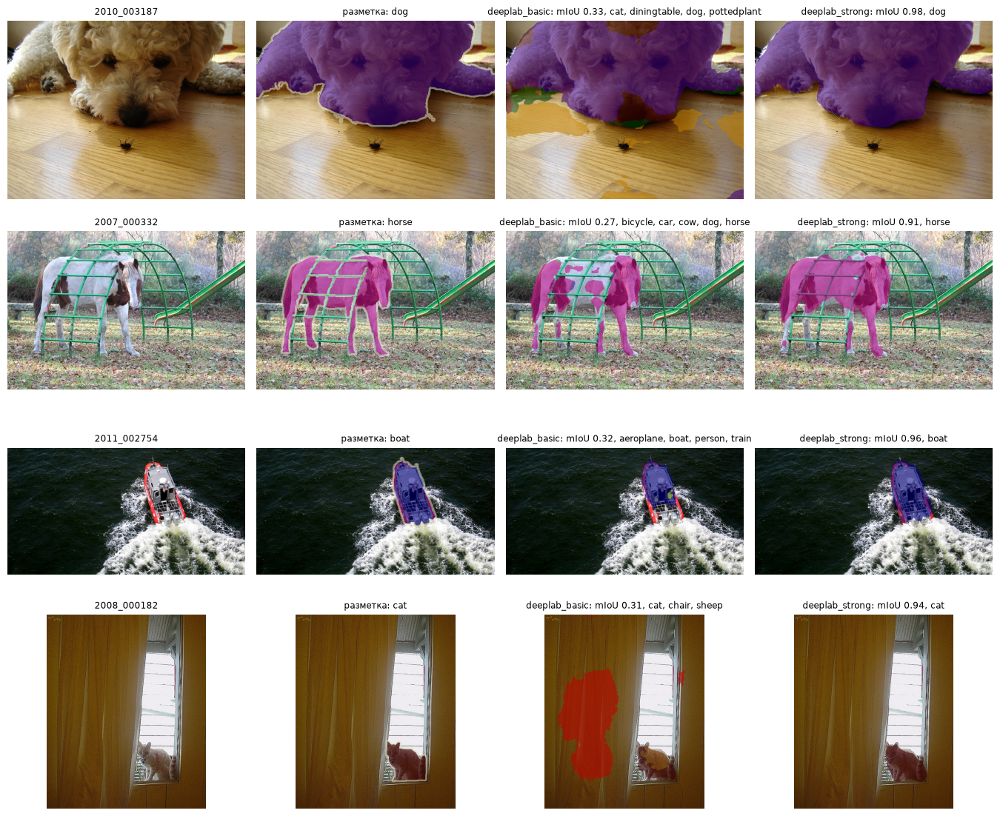

In [23]:
MODELS = {cfg["name"]: load_best(cfg) for cfg in RUNS}


def image_miou(pred, gt):
    return metrics_from_confusion(confusion_matrix(torch.from_numpy(pred.astype(np.int64)), torch.from_numpy(gt.astype(np.int64))))["mIoU"]


def compare_figure(records, path):
    rows, titles = [], []
    for r in records:
        img, gt = imread_rgb(r["image_path"]), read_mask(r["mask_path"])
        preds = {n: predict_mask(m, img) for n, m in MODELS.items()}
        rows.append([img, overlay(img, gt), *[overlay(img, p) for p in preds.values()]])
        titles.append([r["id"], "разметка: " + class_list(r["classes"]),
                       *[(f"{n}: mIoU {image_miou(p, gt):.2f}, " + (class_list(p) or "только фон"))[:70] for n, p in preds.items()]])
    show_grid(rows, titles, path)


per_image = {n: {r["id"]: r["mIoU"] for r in read_csv(RESULTS / "eval" / f"per_image_{n}.csv")} for n in names}
by_id = {r["id"]: r for r in SPLITS["test"]}
rng = random.Random(SEED)
compare_figure(rng.sample(SPLITS["test"], min(6, len(SPLITS["test"]))), RESULTS / "eval" / "examples_random.png")
hardest = sorted(per_image[BEST_RUN], key=per_image[BEST_RUN].get)[:4]
compare_figure([by_id[i] for i in hardest], RESULTS / "eval" / "examples_hardest.png")
if len(names) == 2:
    gain = sorted(per_image[names[1]], key=lambda i: per_image[names[1]][i] - per_image[names[0]][i], reverse=True)[:4]
    compare_figure([by_id[i] for i in gain], RESULTS / "eval" / "examples_strong_gain.png")

## 9. Сравнительный анализ экспериментов и контрольные вопросы

Сводная таблица двух обучений и кривые валидации на одном графике. Числа читаются из `results/`, поэтому ячейка работает и без GPU.

| Эксперимент | аугментации | лучшая эпоха | val mIoU | test mIoU | test mDice | test pixel acc | время | VRAM, ГБ |
|---|---|---|---|---|---|---|---|---|
| deeplab_basic | basic | 26 | 0.640 | 0.660 | 0.782 | 0.920 | 0 ч 19 мин | 3.56 |
| deeplab_strong | strong | 30 | 0.581 | 0.642 | 0.768 | 0.911 | 0 ч 16 мин | 3.56 |

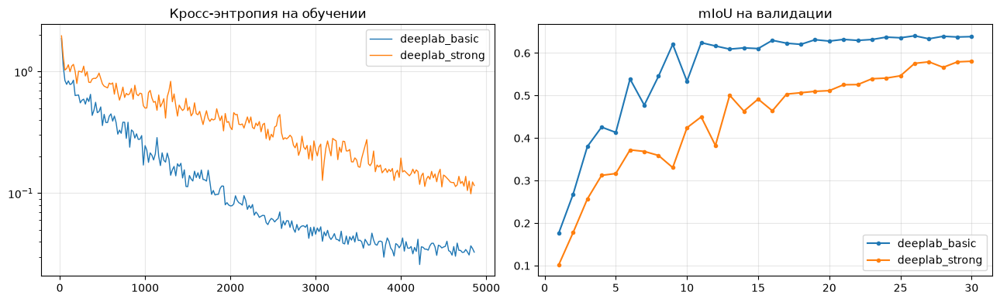

In [24]:
summaries = {n: read_json(RESULTS / n / "summary.json") for n in names}
lines = ["| Эксперимент | аугментации | лучшая эпоха | val mIoU | test mIoU | test mDice | test pixel acc | время | VRAM, ГБ |", "|---|---|---|---|---|---|---|---|---|"]
for n in names:
    s, t = summaries[n], TEST["runs"][n]
    lines.append(f"| {n} | {s['aug']} | {s['best_epoch']} | {s['best_val_mIoU']:.3f} | {t['mIoU']:.3f} | {t['mDice']:.3f} | {t['pixel_acc']:.3f} | "
                 f"{s['total_time']} | {s.get('max_vram_gb', '—')} |")
display(Markdown("\n".join(lines)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for n in names:
    tr, va = read_csv(RESULTS / n / "train_log.csv"), read_csv(RESULTS / n / "val_log.csv")
    axes[0].plot([r["iter"] for r in tr], [r["loss"] for r in tr], linewidth=1, label=n)
    axes[1].plot([r["epoch"] for r in va], [r["mIoU"] for r in va], marker=".", label=n)
axes[0].set_yscale("log")
axes[0].set_title("Кросс-энтропия на обучении")
axes[1].set_title("mIoU на валидации")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "eval" / "compare_curves.png", dpi=110)
plt.show()

**Как читать результаты.** Сильные аугментации обычно дают заметно более низкий loss на обучении у базового варианта (сеть видит одни и те же картинки в одном масштабе и запоминает их), но более высокий mIoU на тесте у варианта strong: разнообразие масштабов и кропов работает как регуляризация и учит модель объектам разного размера. Если разрыв между train loss и val mIoU у basic растёт к концу обучения, это переобучение. Подробные выводы по фактическим числам - в разделе 10.

### Контрольные вопросы

**1. Почему accuracy плохо отражает качество сегментации?**

Pixel accuracy - доля верно размеченных пикселей, и в ней каждый пиксель весит одинаково. В VOC около 70 % пикселей — фон, поэтому предсказатель «всё фон» получает accuracy около 0,7, не найдя ни одного объекта (строка «всё фон» в таблице раздела 7: accuracy высокая, mIoU почти нулевой). Маленькие и редкие классы (bottle, pottedplant) почти не влияют на accuracy: их пиксели составляют доли процента. Accuracy не различает и типы ошибок: пропуск объекта и ложное срабатывание на фоне стоят одинаково. IoU и Dice считаются для каждого класса отдельно относительно размера самого объекта, а усреднение по классам даёт редким классам тот же вес, что и фону. Поэтому модель с accuracy 0,93 может иметь mIoU 0,65: разница и есть реальные ошибки на объектах.

**2. Чем UNet отличается от «обычной» CNN?**

Обычная классификационная CNN - это энкодер: свёртки и пулинг постепенно уменьшают карту признаков (в ResNet в 32 раза) и в конце дают вектор признаков для одной метки на всю картинку. Пространственная информация при этом теряется намеренно. UNet - это энкодер-декодер: после сжатия карта признаков симметрично увеличивается обратно до разрешения входа, и выход - не метка, а карта меток по пикселям. Главная особенность - это skip-соединения: признаки каждого уровня энкодера конкатенируются с признаками декодера того же разрешения, поэтому декодер получает и контекст («что это»), и точные координаты границ («где»), которые были бы потеряны при сжатии. Без skip-соединений границы получаются размытыми. DeepLabv3+ решает ту же задачу иначе: сохраняет разрешение dilated-свёртками и ASPP, а из энкодера берёт только один переход (шаг 4).

## 10. Выводы

**Обучение.** Два прогона по 30 эпох (4860 итераций, батч 8, кроп 512, bf16): 20 и 17 минут на RTX 5060, пик видеопамяти 3,6 ГБ. Тест: 1449 картинок официального val.

| Эксперимент | лучшая эпоха | val mIoU | test mIoU | test mDice | pixel acc | train loss в конце |
|---|---|---|---|---|---|---|
| deeplab_basic | 26 | 0,640 | **0,660** | **0,782** | 0,920 | 0,034 |
| deeplab_strong | 30 | 0,581 | 0,642 | 0,768 | 0,911 | 0,120 |
| «всё фон» | — | — | 0,035 | — | 0,733 | — |

**1. Качество.** mIoU 0,66 при 1300 обучающих картинках и энкодере, предобученном только на ImageNet. Для ориентира: авторские результаты DeepLabv3+ на VOC (около 0,79) получены с предобучением на COCO и на расширенной выборке train_aug из 10 582 картинок, то есть на данных в 8 раз больше. Сильные классы (IoU 0,76–0,85): bus, aeroplane, person, car, cat, sheep, bird - крупные объекты с характерной формой. Слабые: chair 0,25, sofa 0,38, pottedplant 0,46, bicycle 0,49, diningtable 0,49 - тонкие, заставленные или перекрытые предметы. Их главная ошибка - пропуск: 37 % пикселей chair, 39 % pottedplant и 34 % diningtable ушли в фон. Вторая по частоте - путаница похожих классов: sofa → chair 17 %, chair → sofa 13 %, cow → horse 13 %. Самые трудные картинки раздела 8 это подтверждают: диван во весь кадр с кроликом (которого в VOC нет) и бутылка крупным планом размечены как смесь случайных классов, потому что в обучении таких ракурсов не было.

**2. Эксперимент с аугментациями.** При одинаковом бюджете базовые аугментации выиграли: 0,660 против 0,642 mIoU; по отдельным картинкам basic лучше на 601, strong на 461 из 1449 (разница больше 0,02). Причины видны на кривых раздела 9:

- *Бюджет.* У strong валидационная кривая ещё растёт на 30-й эпохе (лучшая эпоха - последняя), а train loss втрое выше (0,12 против 0,034). Случайный масштаб 0,5–2,0 и кроп делают задачу заметно труднее, и за 4860 итераций сеть не успевает её выучить; в работах по DeepLab такие аугментации сочетаются с 30–50 тысячами итераций.
- *Распределение масштабов.* basic видит объекты в том же масштабе, что и на тесте (длинная сторона 512 при исходных ~500 px), strong - в масштабах от 0,5 до 2,0, половина из которых на тесте не встречается.
- *Переобучения у basic нет.* Его val mIoU вышел на плато 0,63–0,64 с 16-й эпохи и не падает, хотя train loss продолжает снижаться. Регуляризация, которую дают сильные аугментации, здесь просто не понадобилась.

Где strong всё же помогает (третья сетка раздела 8): нестандартный масштаб и фон - собака крупным планом, лошадь за решёткой, кот в окне. Там strong даёт mIoU 0,91–0,98 против 0,27–0,33 у basic, который «сыплет» по фону лишними классами. Вывод по эксперименту: сильные аугментации - регуляризация, которая окупается при длинном обучении и защищает от редких ракурсов, но при коротком бюджете она недообучает модель. Честный следующий шаг - 90 эпох для strong или ослабленный диапазон масштаба 0,75–1,5.

**3. Accuracy против mIoU.** Pixel accuracy у обеих моделей 0,91–0,92, разница между ними 0,009; по mIoU разница вдвое больше, 0,018. Предсказатель «всё фон» получает accuracy 0,733 (доля фона в тесте) при mIoU 0,035: accuracy не отличает модель, которая ничего не нашла, от модели, нашедшей две трети объектов.

**4. Что можно улучшить.** Обучение на train_aug (конфиг `segmentation_aug` того же зеркала, 10 582 картинки), энкодер с предобучением на COCO, более длинное обучение для strong, оценка с несколькими масштабами и отражением на инференсе. Видеопамяти использовано меньше половины, так что батч и кроп можно увеличить без смены железа.